[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-molecular-dynamics-course/blob/main/notebooks/05_periodic_boundaries_pme.ipynb)

# 05 · Periodic Boundaries, Cutoffs, and PME Electrostatics

*Practical Molecular Dynamics Course · Hamza Hentabli, Ph.D. · ~50 min*

A simulation box holds a few thousand to a few hundred thousand atoms, yet we want to model a protein in a
*bulk* solution, not a droplet in vacuum. The trick is **periodic boundary conditions**: the box is surrounded
by infinite copies of itself. Then we need to decide how far atoms "see" each other. Lennard-Jones forces die
off fast and can be cut off; electrostatics decays as $1/r$ and cannot. This notebook shows, with real numbers
from a water box, why every modern biomolecular simulation uses **Particle Mesh Ewald (PME)**.

**Learning objectives.** By the end of this notebook you will be able to:

- explain periodic boundary conditions and the minimum image convention
- say why the number of pair interactions forces us to use cutoffs and neighbour lists
- measure how energies and forces depend on the cutoff for reaction-field vs PME electrostatics
- read and tune PME parameters, and apply the rules that link box size and cutoff

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Create the environment from environment.yml once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'openmm'], check=True)
    if not os.path.isdir("practical-molecular-dynamics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-molecular-dynamics-course.git"], check=True)
    DATA_DIR = "practical-molecular-dynamics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. Periodic boundary conditions

Picture the simulation box as one tile of an infinite floor. When an atom leaves through the right face, its
image enters through the left. Each atom interacts with the **nearest image** of every other atom (minimum image
convention). There are no walls and no surface, so a few thousand waters behave like bulk liquid.

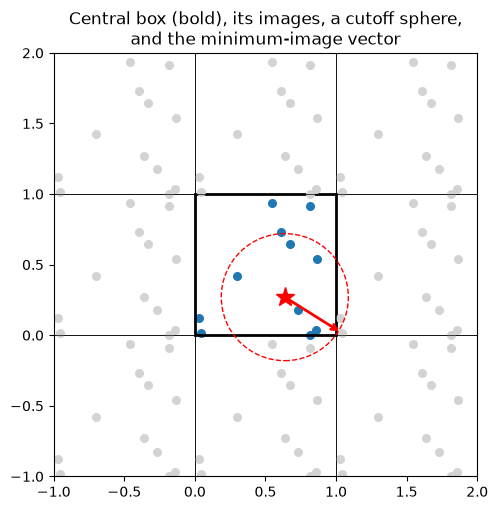

direct vector: [-0.596 -0.253] | minimum-image vector: [ 0.404 -0.253]


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openmm
from openmm import app, unit

rng = np.random.default_rng(0)
Lb = 1.0
pts = rng.uniform(0, Lb, (12, 2))
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for i in (-1, 0, 1):
    for j in (-1, 0, 1):
        ax.scatter(pts[:, 0] + i * Lb, pts[:, 1] + j * Lb, s=30, c="C0" if (i, j) == (0, 0) else "lightgrey")
        ax.add_patch(plt.Rectangle((i * Lb, j * Lb), Lb, Lb, fill=False, lw=2 if (i, j) == (0, 0) else 0.5))
a, b = pts[0], pts[1]
d = b - a; d_min = d - Lb * np.round(d / Lb)
ax.plot(*a, "r*", ms=14)
ax.annotate("", xy=a + d_min, xytext=a, arrowprops=dict(arrowstyle="->", color="r", lw=2))
ax.add_patch(plt.Circle(a, 0.45, fill=False, color="r", ls="--"))
ax.set(xlim=(-1, 2), ylim=(-1, 2), aspect="equal", title="Central box (bold), its images, a cutoff sphere,\nand the minimum-image vector")
plt.show()
print("direct vector:", d.round(3), "| minimum-image vector:", d_min.round(3))

Two rules follow directly:

1. The cutoff must be **less than half the box edge**, or an atom could see two images of the same neighbour
   (OpenMM refuses to run otherwise).
2. A solute must not "see itself": the distance between the solute and its periodic image should exceed the
   cutoff. That is why we pad proteins with ≥1 nm of water (Notebook 07).

## 2. Why cutoffs: counting pairs

A system of $N$ atoms has $N(N-1)/2$ pairs. With a cutoff $r_c$, each atom has only about
$\tfrac43\pi r_c^3 \rho$ neighbours, so the cost grows as $N$ instead of $N^2$. MD codes keep a
**neighbour list** (updated every few steps) so they never test all pairs.

In [3]:
rho = 100.0                                    # atoms per nm^3 in water (about 33 molecules x 3 atoms)
for n_atoms in [3_000, 30_000, 300_000]:
    all_pairs = n_atoms * (n_atoms - 1) / 2
    within = n_atoms * (4 / 3) * np.pi * 1.0**3 * rho / 2
    print(f"{n_atoms:>8,} atoms: {all_pairs:.2e} pairs in total, {within:.2e} within 1 nm  ({all_pairs / within:,.0f}x fewer)")

   3,000 atoms: 4.50e+06 pairs in total, 6.28e+05 within 1 nm  (7x fewer)
  30,000 atoms: 4.50e+08 pairs in total, 6.28e+06 within 1 nm  (72x fewer)
 300,000 atoms: 4.50e+10 pairs in total, 6.28e+07 within 1 nm  (716x fewer)


## 3. A water box to test electrostatics

We build ~1000 TIP3P-FB water molecules and compare electrostatics methods on the **same coordinates**.
The reference is PME with a 1.2 nm cutoff and a very tight error tolerance; we then measure how far each
cheaper method's forces are from it.

In [4]:
ff = app.ForceField("amber14/tip3pfb.xml")
mod = app.Modeller(app.Topology(), [])
mod.addSolvent(ff, boxSize=openmm.Vec3(3.2, 3.2, 3.2) * unit.nanometer)
# relax briefly so the configuration is a realistic liquid
s0 = ff.createSystem(mod.topology, nonbondedMethod=app.PME, nonbondedCutoff=1.0 * unit.nanometer)
i0 = openmm.LangevinMiddleIntegrator(300, 1, 0.002); i0.setRandomNumberSeed(4)
sim0 = app.Simulation(mod.topology, s0, i0, openmm.Platform.getPlatformByName("CPU"))
sim0.context.setPositions(mod.positions); sim0.minimizeEnergy(); sim0.context.setVelocitiesToTemperature(300, 4)
sim0.step(2500)
pos = sim0.context.getState(getPositions=True).getPositions()
n_water = mod.topology.getNumResidues()
print(f"{n_water} waters, {mod.topology.getNumAtoms()} atoms, box edge {mod.topology.getUnitCellDimensions()[0]}")

def energy_forces(method, cutoff, tol=5e-4):
    system = ff.createSystem(mod.topology, nonbondedMethod=method, nonbondedCutoff=cutoff * unit.nanometer,
                             ewaldErrorTolerance=tol)
    ctx = openmm.Context(system, openmm.VerletIntegrator(0.001), openmm.Platform.getPlatformByName("CPU"))
    ctx.setPositions(pos)
    st = ctx.getState(getEnergy=True, getForces=True)
    t0 = time.time()
    for _ in range(20):
        ctx.getState(getForces=True)
    ms = (time.time() - t0) / 20 * 1000
    return (st.getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole) / n_water,
            st.getForces(asNumpy=True).value_in_unit(unit.kilojoule_per_mole / unit.nanometer), ms, system)

E_ref, F_ref, _, _ = energy_forces(app.PME, 1.2, tol=1e-6)
rows = []
for name, method in [("reaction field", app.CutoffPeriodic), ("PME", app.PME)]:
    for rc in [0.6, 0.8, 1.0, 1.2]:
        E, Fo, ms, _ = energy_forces(method, rc)
        rows.append({"method": name, "cutoff (nm)": rc, "E per water (kJ/mol)": E,
                     "E error per water": E - E_ref,
                     "RMS force error (kJ/mol/nm)": np.sqrt(((Fo - F_ref) ** 2).sum(1).mean()),
                     "ms per force evaluation": ms})
cmp = pd.DataFrame(rows)
print(f"reference (PME, 1.2 nm, tolerance 1e-6): {E_ref:.3f} kJ/mol per water")
cmp.round(3)

1074 waters, 3222 atoms, box edge 3.2 nm


reference (PME, 1.2 nm, tolerance 1e-6): -48.956 kJ/mol per water


,method,cutoff (nm),E per water (kJ/mol),E error per water,RMS force error (kJ/mol/nm),ms per force evaluation
0,reaction field,0.6,-47.753,1.202,64.512,2.660
1,reaction field,0.8,-48.568,0.387,37.181,1.819
2,reaction field,1.0,-48.760,0.196,25.159,4.165
3,reaction field,1.2,-48.851,0.105,18.173,4.963
4,PME,0.6,-48.955,0.000,0.845,7.517
5,PME,0.8,-48.957,-0.001,0.742,6.791
6,PME,1.0,-48.957,-0.001,0.639,9.575
7,PME,1.2,-48.955,0.001,0.544,13.061


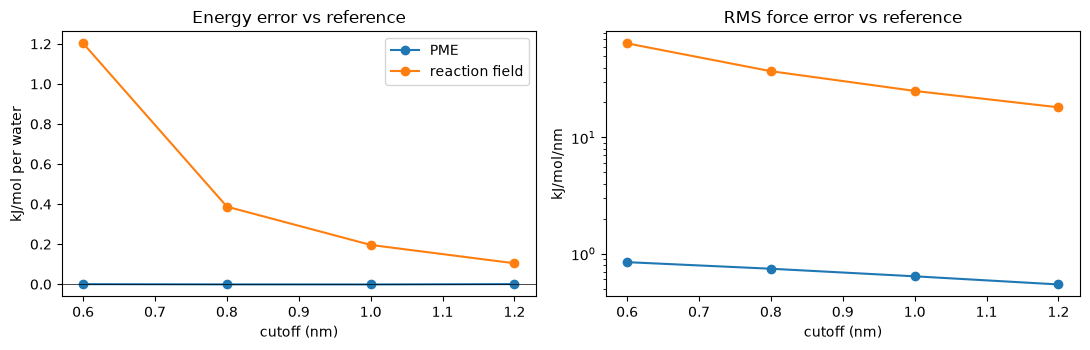

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for name, g in cmp.groupby("method"):
    ax[0].plot(g["cutoff (nm)"], g["E error per water"], "o-", label=name)
    ax[1].plot(g["cutoff (nm)"], g["RMS force error (kJ/mol/nm)"], "o-", label=name)
ax[0].axhline(0, color="k", lw=0.5)
ax[0].set(xlabel="cutoff (nm)", ylabel="kJ/mol per water", title="Energy error vs reference")
ax[1].set(xlabel="cutoff (nm)", ylabel="kJ/mol/nm", title="RMS force error vs reference", yscale="log")
ax[0].legend(); plt.tight_layout(); plt.show()

With a plain cutoff (OpenMM uses the **reaction-field** approximation beyond $r_c$), the energy and forces depend
strongly on the cutoff because the missing $1/r$ tail is large. With PME the real-space cutoff hardly matters:
the long-range part is computed exactly (up to a controllable tolerance) in reciprocal space. That is why PME
lets you use a modest 0.9–1.2 nm cutoff with confidence.

## 4. How Ewald/PME works

Ewald summation splits each $1/r$ interaction into a **short-range** part that dies fast and is summed in real
space within the cutoff, and a **smooth long-range** part that is summed in reciprocal (Fourier) space:

$$\frac{1}{r} = \underbrace{\frac{\operatorname{erfc}(\alpha r)}{r}}_{\text{real space}} + \underbrace{\frac{\operatorname{erf}(\alpha r)}{r}}_{\text{reciprocal space}}$$

PME spreads the charges onto a 3-D grid and uses fast Fourier transforms, so the cost grows as $N\log N$.

PME chosen by OpenMM for tolerance 5e-4: alpha = 2.628 /nm, grid 26 x 26 x 26


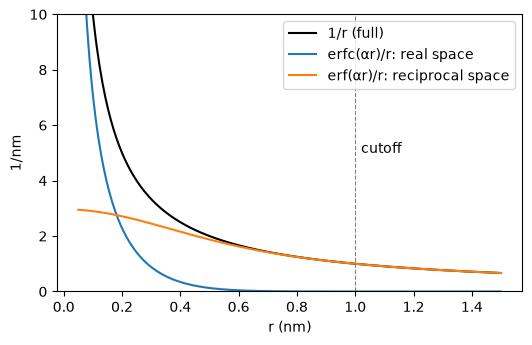

real-space part left at the cutoff: erfc(alpha * 1 nm) = 2.0e-04


In [6]:
from scipy.special import erf, erfc
_, _, _, sys_pme = energy_forces(app.PME, 1.0)
nbf = [f for f in sys_pme.getForces() if isinstance(f, openmm.NonbondedForce)][0]
# (the Reference platform is used here only to read back the parameters OpenMM chose)
ctx = openmm.Context(sys_pme, openmm.VerletIntegrator(0.001), openmm.Platform.getPlatformByName("Reference"))
ctx.setPositions(pos)
alpha, nx, ny, nz = nbf.getPMEParametersInContext(ctx)
print(f"PME chosen by OpenMM for tolerance 5e-4: alpha = {alpha:.3f} /nm, grid {nx} x {ny} x {nz}")

r = np.linspace(0.05, 1.5, 300)
plt.figure(figsize=(6, 3.6))
plt.plot(r, 1 / r, "k", label="1/r (full)")
plt.plot(r, erfc(alpha * r) / r, label="erfc(αr)/r: real space")
plt.plot(r, erf(alpha * r) / r, label="erf(αr)/r: reciprocal space")
plt.axvline(1.0, color="grey", ls="--", lw=0.8); plt.text(1.02, 5, "cutoff")
plt.ylim(0, 10); plt.xlabel("r (nm)"); plt.ylabel("1/nm"); plt.legend(); plt.show()
print(f"real-space part left at the cutoff: erfc(alpha * 1 nm) = {erfc(alpha * 1.0):.1e}")

OpenMM chooses $\alpha$ so that the real-space part left at the cutoff is about the size of the requested `ewaldErrorTolerance`,
then picks a grid fine enough for the same accuracy. The default tolerance (5×10⁻⁴) is a good balance.

## 5. Practical checklist

- Use **PME** for anything with charges; cutoff 0.9–1.2 nm (follow your force field's recommendation:
  AMBER ≈ 0.9–1.0 nm, CHARMM 1.2 nm with a switch from 1.0 nm).
- Keep the **dispersion correction** on for homogeneous liquids (it fixes the density error from truncating LJ).
- Cutoff < half the smallest box width; solute–image distance > cutoff. Check after equilibration, because the
  box shrinks a little under NPT.
- A **truncated octahedron** or **rhombic dodecahedron** box needs ~30% less water than a cube for the same
  solute–image distance (Notebook 11 uses an octahedron).

### ✏️ Exercise 1

Using `cmp`, find the cheapest setting (lowest `ms per force evaluation`) whose RMS force error is below
10 kJ/mol/nm.

In [7]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
ok = cmp[cmp["RMS force error (kJ/mol/nm)"] < 10]
print(ok.sort_values("ms per force evaluation").head(1).T)
```

</details>

### ✏️ Exercise 2

Tighten and loosen the PME tolerance (1e-3, 5e-4, 1e-4, 1e-5) at a 1.0 nm cutoff. For each, print the grid
size chosen by OpenMM and the RMS force error against `F_ref`.

In [8]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
for tol in [1e-3, 5e-4, 1e-4, 1e-5]:
    E, Fo, ms, s = energy_forces(app.PME, 1.0, tol=tol)
    c = openmm.Context(s, openmm.VerletIntegrator(0.001), openmm.Platform.getPlatformByName("Reference")); c.setPositions(pos)
    nb_ = [f for f in s.getForces() if isinstance(f, openmm.NonbondedForce)][0]
    print(tol, nb_.getPMEParametersInContext(c)[1:], round(np.sqrt(((Fo - F_ref) ** 2).sum(1).mean()), 3), f"{ms:.1f} ms")
```

</details>

### ✏️ Exercise 3

What happens if the cutoff is larger than half the box? Try `energy_forces(app.PME, 1.7)` and read the error
message.

In [9]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
try:
    energy_forces(app.PME, 1.7)
except Exception as err:
    print(type(err).__name__, ":", err)
```

</details>

## Key takeaways

- Periodic boundaries remove surfaces; each atom sees the nearest image of every other atom.
- Cutoffs and neighbour lists turn an N² problem into an N problem.
- Electrostatics with a plain cutoff depends strongly on the cutoff; PME is accurate with a modest cutoff.
- Cutoff < half the box, solute–image distance > cutoff, and PME with default tolerance are the safe defaults.

**Next:** [06 · Preparing a protein for simulation](06_preparing_a_protein.ipynb).